In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
from ydata_profiling import ProfileReport#EDA
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import warnings
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
import pickle
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("C:/Users/periy/OneDrive/Desktop/Datamites/Machine learning/Feature Engineering/loan_approved.csv")

In [3]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
df.isnull().sum()

Loan_ID                    0
Gender                    13
Married                    3
Dependents                15
Education                  0
Self_Employed             32
ApplicantIncome            0
CoapplicantIncome          0
LoanAmount                22
Loan_Amount_Term          14
Credit_History            50
Property_Area              0
Loan_Status (Approved)     0
dtype: int64

In [5]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [6]:
df.describe(include ='object')

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status (Approved)
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


In [7]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

In [8]:
df.shape

(614, 13)

In [9]:
df.loc[df['Gender'].isnull(),'Gender']="Male"  # We have imputed the null values with the Male

In [10]:
df['Gender'].isnull().sum()

np.int64(0)

In [11]:
df.loc[df['Credit_History'].isnull(),'Credit_History']=0.0 # We have imputed the null values with the 0

In [12]:
df['Credit_History'].isnull().sum()

np.int64(0)

In [13]:
df.loc[df['LoanAmount'].isnull(),'LoanAmount']=df['LoanAmount'].median() # We have imputed the null values with the median

In [24]:
df['LoanAmount'].isnull().sum()

np.int64(0)

In [34]:
df.loc[df['Loan_Amount_Term'].isnull(),'Loan_Amount_Term']=360.0 #mean

In [35]:
df['Loan_Amount_Term'].isnull().sum()

np.int64(0)

In [36]:
df.loc[df['Dependents'].isnull(),'Dependents']='0' #top = 0

In [37]:
df['Dependents'].isnull().sum()

np.int64(0)

In [42]:
df.loc[df['Self_Employed'].isnull(),'Self_Employed']='No' #top = 0

In [45]:
df.loc[df['Married'].isnull(),'Married']='Yes'

In [46]:
df.isnull().sum()

Loan_ID                   0
Gender                    0
Married                   0
Dependents                0
Education                 0
Self_Employed             0
ApplicantIncome           0
CoapplicantIncome         0
LoanAmount                0
Loan_Amount_Term          0
Credit_History            0
Property_Area             0
Loan_Status (Approved)    0
dtype: int64

# Outliers

In [47]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Loan_ID                 614 non-null    object 
 1   Gender                  614 non-null    object 
 2   Married                 614 non-null    object 
 3   Dependents              614 non-null    object 
 4   Education               614 non-null    object 
 5   Self_Employed           614 non-null    object 
 6   ApplicantIncome         614 non-null    int64  
 7   CoapplicantIncome       614 non-null    float64
 8   LoanAmount              614 non-null    float64
 9   Loan_Amount_Term        614 non-null    float64
 10  Credit_History          614 non-null    float64
 11  Property_Area           614 non-null    object 
 12  Loan_Status (Approved)  614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


<Axes: xlabel='LoanAmount'>

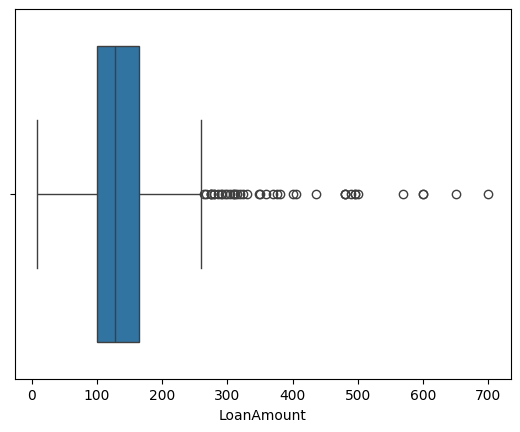

In [50]:
sns.boxplot(x=df.LoanAmount ,orient='h')

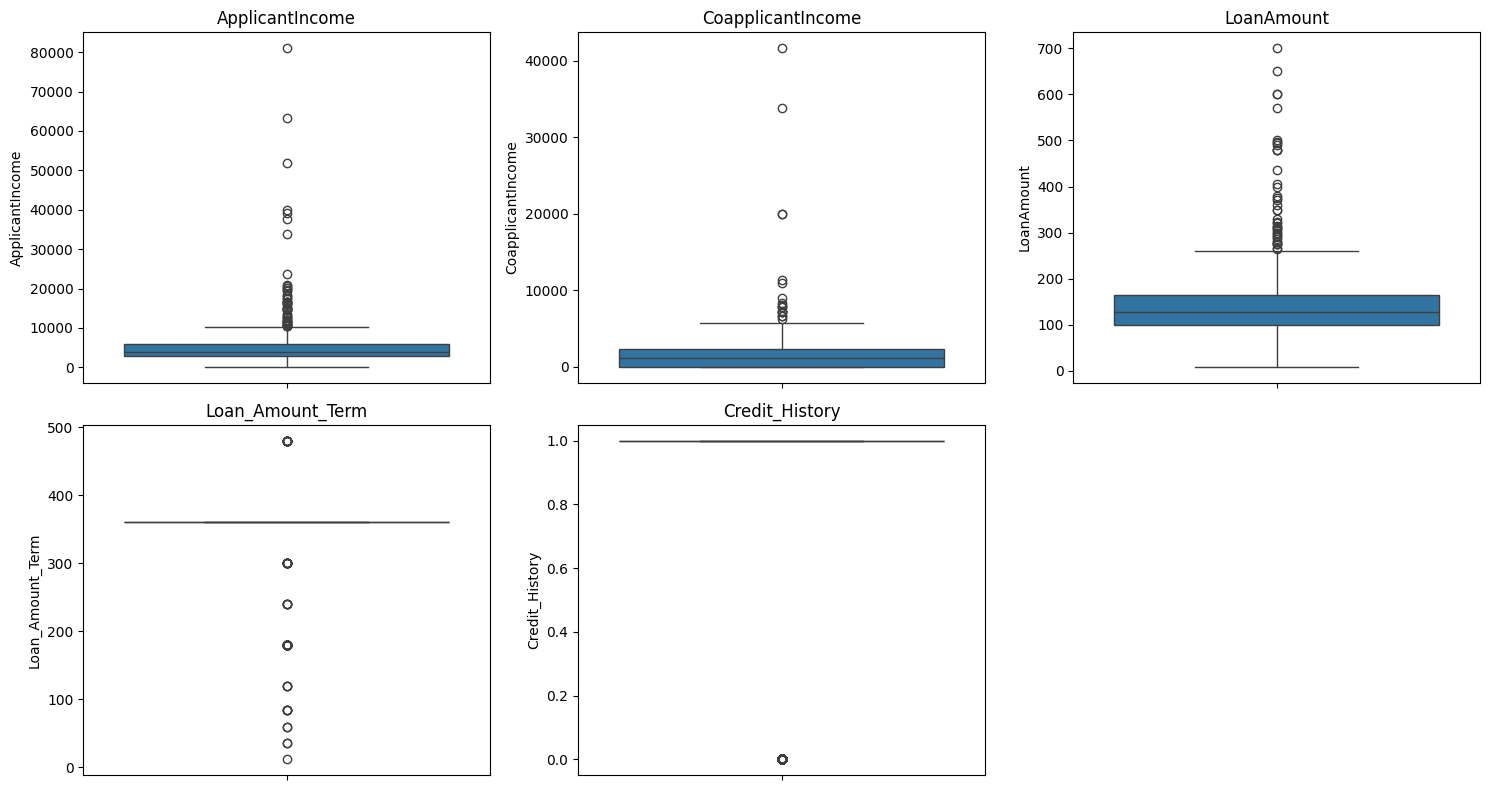

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(15, 8))

for i, col in enumerate(num_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [54]:
#Important: Don't use boxplots directly on columns like Gender, Married, Education, etc., because they are categorical (object) columns.

# Handling the outliers :

# Using Winsorize Method to handle outliers :

In [59]:
from scipy.stats.mstats import winsorize

# Specify the percentage of data to be trimmed from both ends
trim_percentage = 0.10

# Winsorize the specified column
df['ApplicantIncome'] = winsorize(df['ApplicantIncome'], limits=trim_percentage)

<Axes: xlabel='ApplicantIncome'>

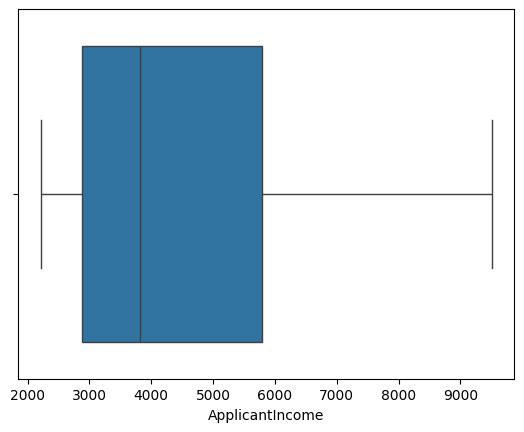

In [60]:
sns.boxplot(x=df.ApplicantIncome ,orient='h')

In [61]:
from scipy.stats.mstats import winsorize

# Specify the percentage of data to be trimmed from both ends
trim_percentage = 0.05

# Winsorize the specified column
df['CoapplicantIncome'] = winsorize(df['CoapplicantIncome'], limits=trim_percentage)

<Axes: xlabel='CoapplicantIncome'>

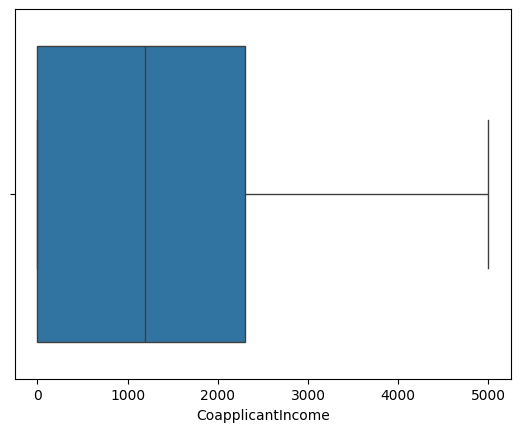

In [62]:
sns.boxplot(x=df.CoapplicantIncome ,orient='h')

In [65]:
from scipy.stats.mstats import winsorize

# Specify the percentage of data to be trimmed from both ends
trim_percentage = 0.10

# Winsorize the specified column
df['LoanAmount'] = winsorize(df['LoanAmount'], limits=trim_percentage)

<Axes: xlabel='LoanAmount'>

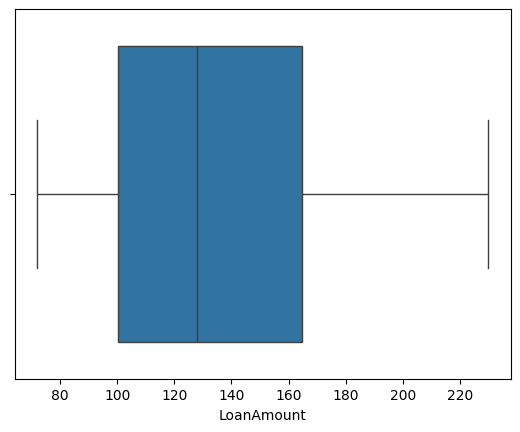

In [66]:
sns.boxplot(x=df.LoanAmount ,orient='h')

# Now we can be able to see that the outliers were sorted.

# Using IQR method to handle the outliers :

In [67]:
import numpy as np
import pandas as pd

# Calculate quartiles
Q1 = df['LoanAmount'].quantile(0.25)
Q3 = df['LoanAmount'].quantile(0.75)

In [68]:
IQR = Q3 - Q1
IQR

np.float64(64.5)

In [69]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


In [70]:
print(lower_bound)
print(upper_bound)

3.5
261.5


In [71]:
df = df[(df['LoanAmount'] >= lower_bound) & (df['LoanAmount'] <= upper_bound)]

<Axes: xlabel='LoanAmount'>

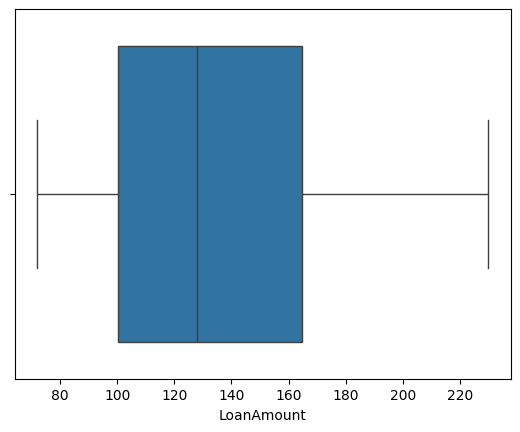

In [72]:
sns.boxplot(x=df.LoanAmount ,orient='h')

In [73]:
Q1 = df['CoapplicantIncome'].quantile(0.25)
Q3 = df['CoapplicantIncome'].quantile(0.75)


In [74]:
IQR = Q3 - Q1
IQR

np.float64(2297.25)

In [75]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


In [76]:
print(lower_bound)
print(upper_bound)

-3445.875
5743.125


In [77]:
df = df[(df['CoapplicantIncome'] >= lower_bound) & (df['CoapplicantIncome'] <= upper_bound)]

<Axes: xlabel='CoapplicantIncome'>

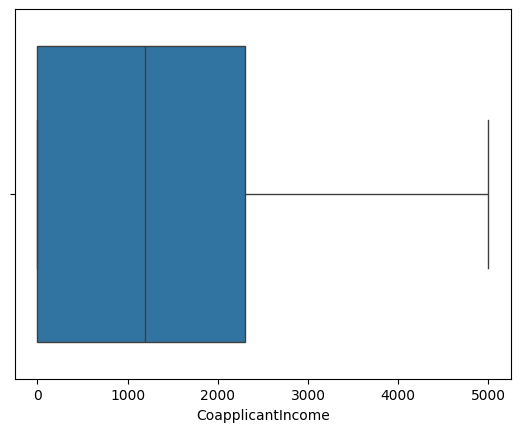

In [79]:
sns.boxplot(x=df.CoapplicantIncome ,orient='h')

In [81]:
Q1 = df['ApplicantIncome'].quantile(0.25)
Q3 = df['ApplicantIncome'].quantile(0.75)


In [82]:
IQR = Q3 - Q1
IQR

np.float64(2917.5)

In [83]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


In [84]:
print(lower_bound)
print(upper_bound)

-1498.75
10171.25


<Axes: xlabel='ApplicantIncome'>

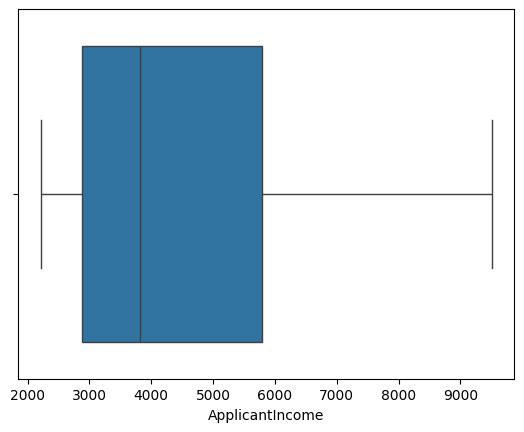

In [85]:
sns.boxplot(x=df.ApplicantIncome ,orient='h')


In [88]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

In [89]:
df['Married'].value_counts()

Married
Yes    401
No     213
Name: count, dtype: int64

In [86]:
for col in df.columns:
    print("\n", col)
    print(df[col].value_counts())


 Loan_ID
Loan_ID
LP001002    1
LP002328    1
LP002305    1
LP002308    1
LP002314    1
           ..
LP001692    1
LP001693    1
LP001698    1
LP001699    1
LP002990    1
Name: count, Length: 614, dtype: int64

 Gender
Gender
Male      502
Female    112
Name: count, dtype: int64

 Married
Married
Yes    401
No     213
Name: count, dtype: int64

 Dependents
Dependents
0     360
1     102
2     101
3+     51
Name: count, dtype: int64

 Education
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

 Self_Employed
Self_Employed
No     500
Yes     82
0       32
Name: count, dtype: int64

 ApplicantIncome
ApplicantIncome
9504    62
2214    62
2500     9
2600     6
4583     6
        ..
4009     1
2221     1
3727     1
3850     1
7583     1
Name: count, Length: 394, dtype: int64

 CoapplicantIncome
CoapplicantIncome
0.0       273
5000.0     31
2500.0      5
1666.0      5
2083.0      5
         ... 
2791.0      1
1010.0      1
1695.0      1
2598.0      1
240.0       1


### Steps of preprocesing for features:
- LabelEncoder for Married,Credit_history
- OrdinalEncoder for Dependents,Education
- One hot encoder for Self Employed,Property_area,Gender
### Steps of preprocessing for Label
- LabelEncoder for Loan_Status (Approved)

In [90]:
df=df.drop(['Dependents'], axis=1)

In [91]:
df_encoded = pd.get_dummies(df, columns=['Married'], prefix='Married')

In [92]:
df_encoded.columns

Index(['Loan_ID', 'Gender', 'Education', 'Self_Employed', 'ApplicantIncome',
       'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History',
       'Property_Area', 'Loan_Status (Approved)', 'Married_No', 'Married_Yes'],
      dtype='object')

In [93]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

# Fit and transform the 'matchType' column to obtain label-encoded values
df['Married'] = encoder.fit_transform(df['Married'])

# Display the result
print(df[['Married']])

     Married
0          0
1          1
2          1
3          1
4          0
..       ...
609        0
610        1
611        1
612        1
613        0

[614 rows x 1 columns]


In [101]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

# Fit and transform the 'matchType' column to obtain label-encoded values
df['Credit_History'] = encoder.fit_transform(df['Credit_History'])

# Display the result
print(df[['Credit_History']])

     Credit_History
0                 1
1                 1
2                 1
3                 1
4                 1
..              ...
609               1
610               1
611               1
612               1
613               0

[614 rows x 1 columns]


In [94]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

# Fit and transform the 'matchType' column to obtain label-encoded values
df['Loan_Status (Approved)'] = encoder.fit_transform(df['Loan_Status (Approved)'])

# Display the result
print(df[['Loan_Status (Approved)']])

     Loan_Status (Approved)
0                         1
1                         0
2                         1
3                         1
4                         1
..                      ...
609                       1
610                       1
611                       1
612                       1
613                       0

[614 rows x 1 columns]


In [95]:
df.Education.value_counts()

Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

In [98]:
Education_enc=OrdinalEncoder(categories=[['Graduate', 'Not Graduate']])

In [99]:
df['Education'] = encoder.fit_transform(df[['Education']])

In [100]:
df.Education.value_counts()

Education
0    480
1    134
Name: count, dtype: int64

In [106]:
df = pd.get_dummies(
    df,
    columns=['Self_Employed', 'Property_Area', 'Gender'],
    drop_first=True
)

In [109]:
df.columns

Index(['Loan_ID', 'Married', 'Education', 'ApplicantIncome',
       'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History',
       'Loan_Status (Approved)', 'Self_Employed_No', 'Self_Employed_Yes',
       'Property_Area_Semiurban', 'Property_Area_Urban', 'Gender_Male'],
      dtype='object')

In [111]:
encoded_cols = [
    'Self_Employed_No',
    'Self_Employed_Yes',
    'Property_Area_Semiurban',
    'Property_Area_Urban',
    'Gender_Male'
]

df[encoded_cols] = df[encoded_cols].astype(int)

In [112]:
df.head()

,Loan_ID,Married,Education,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status (Approved),Self_Employed_No,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban,Gender_Male
0,LP001002,0,0,5849,0.0,128.0,360.0,1,1,1,0,0,1,1
1,LP001003,1,0,4583,1508.0,128.0,360.0,1,0,1,0,0,0,1
2,LP001005,1,0,3000,0.0,72.0,360.0,1,1,0,1,0,1,1
3,LP001006,1,1,2583,2358.0,120.0,360.0,1,1,1,0,0,1,1
4,LP001008,0,0,6000,0.0,141.0,360.0,1,1,1,0,0,1,1


In [113]:
df.drop('Loan_ID', axis=1, inplace=True)

In [115]:
df.columns

Index(['Married', 'Education', 'ApplicantIncome', 'CoapplicantIncome',
       'LoanAmount', 'Loan_Amount_Term', 'Credit_History',
       'Loan_Status (Approved)', 'Self_Employed_No', 'Self_Employed_Yes',
       'Property_Area_Semiurban', 'Property_Area_Urban', 'Gender_Male'],
      dtype='object')

In [116]:
df = df.drop('Self_Employed_No', axis=1)

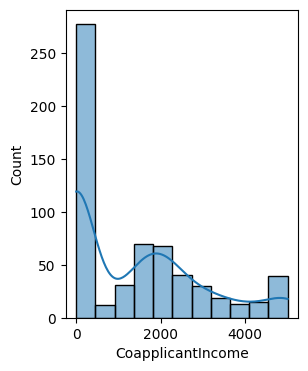

In [117]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'], kde= True) # left screwed
plt.show()

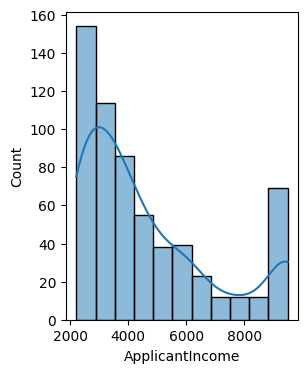

In [118]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome'], kde= True) # left screwed
plt.show()

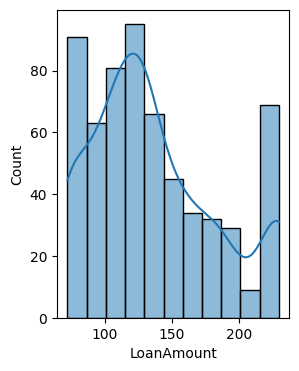

In [119]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'], kde= True) # left screwed
plt.show()

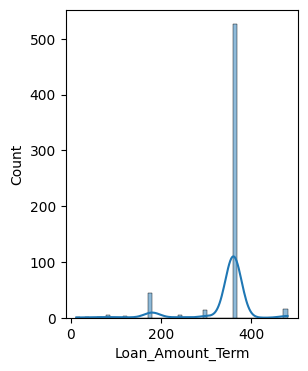

In [121]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['Loan_Amount_Term'], kde= True) # right screwed
plt.show()

## We are able to see that some of columns were right skewed and some were left skewed.
### so we will using different transformation for different columns.

In [122]:
df['CoapplicantIncome']=np.log(df['CoapplicantIncome'])

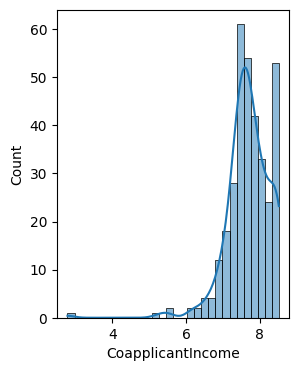

In [123]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['CoapplicantIncome'], kde= True) # Target columns
plt.show()

In [124]:
df['ApplicantIncome_exponential']=df.ApplicantIncome**(1/1.2)

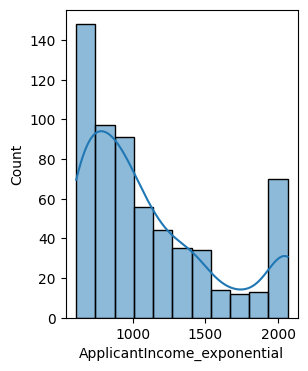

In [125]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['ApplicantIncome_exponential'], kde= True)
plt.show()

In [127]:
from scipy.stats import boxcox
transformed_data, lambda_value = boxcox(df['Loan_Amount_Term'])

In [128]:
print("Transformed data:", transformed_data)

Transformed data: [1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 6.23871576e+05 1.71794525e+07
 5.05335632e+06 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 1.71794525e+07 1.71794525e+07
 1.71794525e+07 1.71794525e+07 2.12092220e+06 1.71794525e+07
 1.717

In [129]:
print("Lambda value:", lambda_value)

Lambda value: 3.01792025163975


In [130]:
df['LoanAmount']=df.LoanAmount**(1/2) # this column is right screw


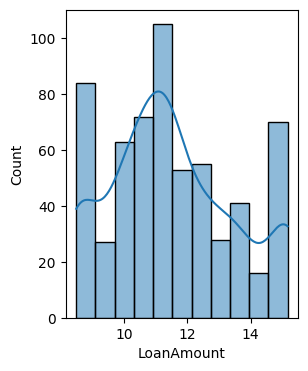

In [131]:
plt.figure(figsize=(3,4))
sns.histplot(x=df['LoanAmount'], kde= True)
plt.show()

In [132]:
df.columns

Index(['Married', 'Education', 'ApplicantIncome', 'CoapplicantIncome',
       'LoanAmount', 'Loan_Amount_Term', 'Credit_History',
       'Loan_Status (Approved)', 'Self_Employed_Yes',
       'Property_Area_Semiurban', 'Property_Area_Urban', 'Gender_Male',
       'ApplicantIncome_exponential'],
      dtype='object')

In [133]:
X=df.drop(['Loan_Status (Approved)'],axis=1)
Y=df['Loan_Status (Approved)']

In [135]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test= train_test_split(X,Y,test_size=0.3,random_state=42)

In [138]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [141]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Replace infinity
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Fill missing values using training median
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [142]:
X_train_scaled.shape
X_test_scaled.shape

(185, 12)

In [154]:
df.columns

Index(['Married', 'Education', 'ApplicantIncome', 'CoapplicantIncome',
       'LoanAmount', 'Loan_Amount_Term', 'Credit_History',
       'Loan_Status (Approved)', 'Self_Employed_Yes',
       'Property_Area_Semiurban', 'Property_Area_Urban', 'Gender_Male',
       'ApplicantIncome_exponential'],
      dtype='object')

In [155]:
df = df.drop('ApplicantIncome_exponential', axis=1)

In [156]:
df.columns

Index(['Married', 'Education', 'ApplicantIncome', 'CoapplicantIncome',
       'LoanAmount', 'Loan_Amount_Term', 'Credit_History',
       'Loan_Status (Approved)', 'Self_Employed_Yes',
       'Property_Area_Semiurban', 'Property_Area_Urban', 'Gender_Male'],
      dtype='object')

In [158]:
df = df.rename(columns={
    'Property_Area_Urban': 'Property_Area'
    
})

In [162]:
df = df.rename(columns={
    'Self_Employed_Yes': 'Self_Employed'
    
})

In [163]:
df = df.rename(columns={
    'Gender_Male': 'Gender'
    
})

In [166]:
df.columns

Index(['Married', 'Education', 'ApplicantIncome', 'CoapplicantIncome',
       'LoanAmount', 'Loan_Amount_Term', 'Credit_History',
       'Loan_Status (Approved)', 'Self_Employed', 'Property_Area', 'Gender'],
      dtype='object')

In [167]:
from sklearn.preprocessing import MinMaxScaler

# Define the MinMaxScaler object
scaler = MinMaxScaler()

In [169]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled

array([[ 0.77507823,  1.87504386, -0.94201946, ...,  1.40682858,
         0.49343516, -0.97329514],
       [ 0.77507823,  1.87504386, -0.75496467, ..., -0.71081865,
         0.49343516, -0.7630296 ],
       [-1.29019234, -0.53332086, -1.04404934, ..., -0.71081865,
         0.49343516, -1.09059888],
       ...,
       [-1.29019234, -0.53332086, -0.60914696, ...,  1.40682858,
        -2.02660871, -0.60282751],
       [ 0.77507823, -0.53332086,  2.05510843, ..., -0.71081865,
        -2.02660871,  2.0102813 ],
       [ 0.77507823, -0.53332086,  2.05510843, ...,  1.40682858,
         0.49343516,  2.0102813 ]], shape=(429, 12))

In [170]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()


In [171]:
categorical_cols_to_encode = ['Gender', 'Self_Employed', 'Property_Area']

In [175]:
train_cols = X_train.columns
test_cols = X_test.columns

missing_in_test = set(train_cols) - set(test_cols)
for c in missing_in_test:
    X_test[c] = 0

missing_in_train = set(test_cols) - set(train_cols)
for c in missing_in_train:
    X_train[c] = 0

X_test = X_test[train_cols] # Ensure the order is the same

# Replace any infinite values with 0 before scaling
X_train.replace([np.inf, -np.inf], 0, inplace=True)
X_test.replace([np.inf, -np.inf], 0, inplace=True)

from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()

X_train_rf = scaler.fit_transform(X_train)
X_test_rf = scaler.transform(X_test)

In [176]:
X_train_rf

array([[ 0.        ,  1.        , -0.45436893, ...,  1.        ,
         0.        , -0.47860509],
       [ 0.        ,  1.        , -0.31197411, ...,  0.        ,
         0.        , -0.32463144],
       [-1.        ,  0.        , -0.53203883, ...,  0.        ,
         0.        , -0.56450449],
       ...,
       [-1.        ,  0.        , -0.20097087, ...,  1.        ,
        -1.        , -0.20731836],
       [ 0.        ,  0.        ,  1.82718447, ...,  0.        ,
        -1.        ,  1.70621381],
       [ 0.        ,  0.        ,  1.82718447, ...,  1.        ,
         0.        ,  1.70621381]], shape=(429, 12))

In [177]:
X_test_rf 

array([[ 0.        ,  0.        ,  1.69093851, ...,  0.        ,
         0.        ,  1.58653482],
       [ 0.        ,  0.        ,  0.14627832, ...,  0.        ,
         0.        ,  0.14737566],
       [ 0.        ,  0.        ,  0.1       , ...,  0.        ,
         0.        ,  0.10104201],
       ...,
       [ 0.        ,  0.        ,  1.82718447, ...,  1.        ,
         0.        ,  1.70621381],
       [ 0.        ,  0.        , -0.25339806, ...,  0.        ,
         0.        , -0.26245326],
       [ 0.        ,  0.        ,  0.53139159, ...,  0.        ,
        -1.        ,  0.52385431]], shape=(185, 12))

In [186]:
X = df.drop('Loan_Status (Approved)', axis=1)
y = df['Loan_Status (Approved)']

In [187]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(y_train.shape)

(491, 10)
(491,)


In [188]:
categorical_cols_to_encode = [
    'Gender',
    'Self_Employed',
    'Property_Area'
]

X_train = pd.get_dummies(
    X_train,
    columns=categorical_cols_to_encode,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_cols_to_encode,
    drop_first=True,
    dtype=int
)

In [189]:
X_train, X_test = X_train.align(
    X_test,
    join='left',
    axis=1,
    fill_value=0
)

In [191]:
import numpy as np

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())

In [192]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_train_rf = scaler.fit_transform(X_train)
X_test_rf = scaler.transform(X_test)

In [193]:
print(X_train_rf.shape)
print(y_train.shape)

(491, 10)
(491,)


In [194]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_rf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [195]:
model.fit(X_train_rf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [196]:
y_pred = model.predict(X_test_rf)

In [197]:
y_pred[:10]

array([1, 0, 1, 1, 1, 1, 1, 1, 1, 1])

In [198]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.7723577235772358


In [199]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[22 21]
 [ 7 73]]


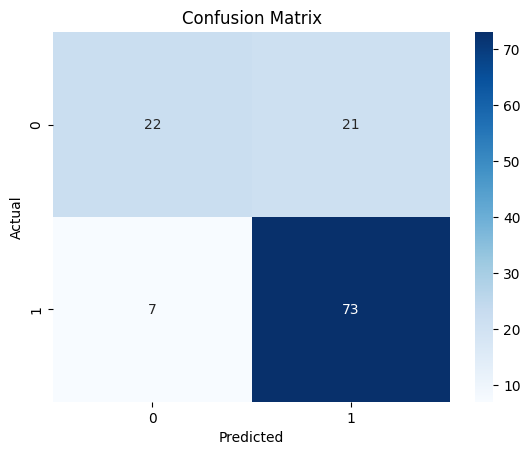

In [200]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.show()

In [201]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.776595744680851
Recall: 0.9125
F1 Score: 0.8390804597701149
